<a href="https://colab.research.google.com/github/TejasDharmale/Bayesian-machine-learning-assignment/blob/main/Bayesian_machine_learning_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>



#### Name: Tejas Dharmale
#### Student Number : S1190137



##Project: III. Decision-making Under Uncertainty with Bayesian Optimization

In [2]:
# Problem: Before it was too difficult to identify the best point of an unknown, expensive function using the minimum number of evaluations
# for example when tuning the hyperparameters of a model that takes hours to train.

# I selected Bayesian Optimization due to its application of probabilities to make more informed decisions
# through identifying the optimal point for evaluation, considering that evaluations are costly and the function is not known
#The GP makes a prediction for the mean and variance of each point using just a few observations, which is utilized by the selection(acquisition) function

In [4]:
!pip install -q jaxopt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.4/172.4 kB 4.5 MB/s eta 0:00:00


In [5]:
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp
import jax.random as jr
import jaxopt
from jax import flatten_util
from jax.scipy.linalg import solve_triangular
jax.config.update('jax_enable_x64', True)

### 1.1 Test function and initial observations


In [6]:

def target_func(x):

    x_val = x[:, 0]
    return jnp.sin(3 * jnp.pi * x_val) + 0.5 * jnp.sin(7 * jnp.pi * x_val)

rng = jr.PRNGKey(42)
rng, subkey = jr.split(rng)


X = jr.uniform(subkey, shape=(5, 1), minval=0.0, maxval=1.0)
y = target_func(X)

X_test = jnp.linspace(0, 1, 200)[:, None]

In [3]:
#1.1 Test function and initial observations
# I define a test function with a known formula.(sin(3pix) + 0.5 sin(7pix)
# then we randomly select 5 points and evaluate the function at them
# Using a known function it helps us to test how Bayesian Optimization works and compare its predictions with the true function values
# We have created 200 testing data points for comparison between the predicted and actual function value of GP on all the points from the interval.

### 1.2 Gaussian Process: kernel, posterior and prediction

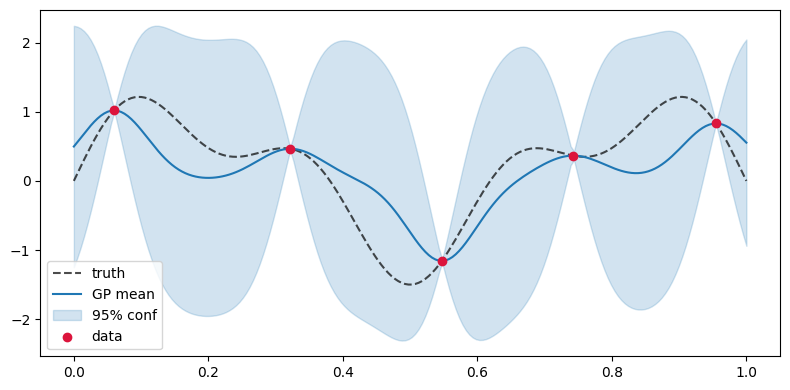

In [7]:
def f(x):
    x_val = x[:, 0]
    return jnp.sin(3 * jnp.pi * x_val) + 0.5 * jnp.sin(7 * jnp.pi * x_val)

key = jr.PRNGKey(42)
key, subkey = jr.split(key)
X = jr.uniform(subkey, shape=(5, 1), minval=0.0, maxval=1.0)
y = f(X)

X_test = jnp.linspace(0, 1, 200)[:, None]

def rbf_kernel(x1, x2, params):
    length_scale, signal_std = params

    diff = x1[:, None, :] - x2[None, :, :]
    dist_sq = jnp.sum(diff ** 2, axis=-1)

    return (signal_std ** 2) * jnp.exp(-dist_sq / (2.0 * length_scale ** 2))

def compute_gp_posterior(train_data, X_test, kernel_fn, params, noise=1e-3):
    X_train, y_train = train_data
    N = len(X_train)

    K = kernel_fn(X_train, X_train, params)
    K = K + (noise ** 2) * jnp.eye(N)

    K_s = kernel_fn(X_train, X_test, params)
    K_ss = kernel_fn(X_test, X_test, params)

    L = jnp.linalg.cholesky(K)
    tmp = solve_triangular(L, y_train, lower=True)
    alpha = solve_triangular(L.T, tmp, lower=False)

    mean = (K_s.T @ alpha).squeeze()

    v = solve_triangular(L, K_s, lower=True)
    cov = K_ss - v.T @ v

    return mean, cov

gp_params = (jnp.array([0.05]), jnp.array([1.0]))
mu, cov_mat = compute_gp_posterior((X, y), X_test, rbf_kernel, gp_params)
std_dev = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

plt.figure(figsize=(8, 4))
plt.plot(X_test[:, 0], f(X_test), 'k--', label='truth', alpha=0.7)
plt.plot(X_test[:, 0], mu, color='tab:blue', label='GP mean')

plt.fill_between(
    X_test[:, 0],
    mu - 2 * std_dev,
    mu + 2 * std_dev,
    color='tab:blue',
    alpha=0.2,
    label='95% conf'
)

plt.scatter(X[:, 0], y, c='crimson', zorder=5, label='data')
plt.legend(loc='best')
plt.tight_layout()
plt.show()


In [8]:
# 1.2 Gaussian Process: kernel, posterior and prediction
# The GP makes a prediction of the function value at any location along with the uncertainty.
# The kernel I have used is the RBF(radial basis function) kernel (length scale 0.1 and signal std 1.0).
# The posterior is estimated by using the five observations with Cholesky Decomposition.
# what is cholesky decomposition, so basically it is used instead of directly inverting this matrix
# Graph Plot: The dotted line represents the actual function, red dots represent the five observations,
# blue line represents the GP mean and blue band represents the uncertainty.
# The acquisition function will use this uncertainty for making the next choice of point.

#UCB acquisition

Beta 0.0 suggests next sample at x = 0.688
Beta 2.0 suggests next sample at x = 0.201
Beta 10.0 suggests next sample at x = 0.191


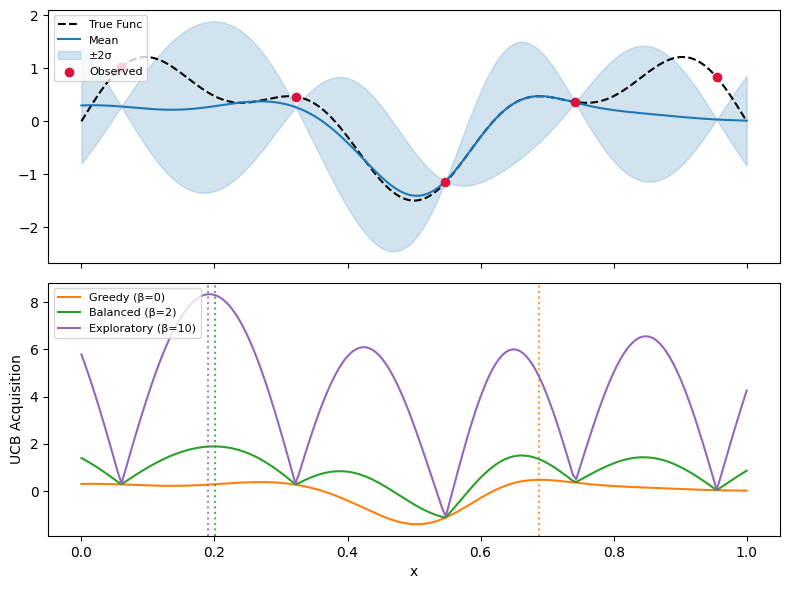

In [20]:
sigma = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

def calc_ucb(mean, std, weight):
    return mean + weight * std

fig, (ax_gp, ax_acq) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax_gp.plot(X_test[:, 0], f(X_test), 'k--', label='True Func')
ax_gp.plot(X_test[:, 0], mu, color='tab:blue', label='Mean')
ax_gp.fill_between(X_test[:, 0], mu - 2*sigma, mu + 2*sigma, color='tab:blue', alpha=0.2, label='±2σ')
ax_gp.scatter(X[:, 0], y, color='crimson', zorder=5, label='Observed')
ax_gp.legend(loc='upper left', fontsize=8)

beta_configs = [
    (0.0, 'tab:orange', 'Greedy (β=0)'),
    (2.0, 'tab:green', 'Balanced (β=2)'),
    (10.0, 'tab:purple', 'Exploratory (β=10)')
]

for beta, color, label_text in beta_configs:
    ucb_score = calc_ucb(mu, sigma, beta)
    best_idx = jnp.argmax(ucb_score)

    ax_acq.plot(X_test[:, 0], ucb_score, color=color, label=label_text)
    ax_acq.axvline(X_test[best_idx, 0], color=color, linestyle=':', alpha=0.8)

    print(f"Beta {beta} suggests next sample at x = {float(X_test[best_idx, 0]):.3f}")

ax_acq.legend(loc='upper left', fontsize=8)
ax_acq.set_ylabel('UCB Acquisition')
ax_acq.set_xlabel('x')

plt.tight_layout()
plt.show()


### 3.1 The Bayesian optimization loop

#### Reference1 : https://gaussianprocess.org/gpml/chapters/RW2.pdf?utm_source
#### Reference 2: https://distill.pub/2019/visual-exploration-gaussian-processes/?utm_source

β=0.0, seed=1: final regret = 0.000
   picks: [0.76, 0.18, 0.2, 0.01, 0.1, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09, 0.09]
β=0.0, seed=2: final regret = 0.002
   picks: [0.92, 0.89, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=0.0, seed=3: final regret = 0.749
   picks: [0.35, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3, 0.3]
β=2.0, seed=1: final regret = 0.000
   picks: [0.86, 0.07, 1.0, 0.15, 0.0, 0.77, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=2.0, seed=2: final regret = 0.000
   picks: [1.0, 0.14, 0.79, 0.0, 0.23, 0.87, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9, 0.9]
β=2.0, seed=3: final regret = 0.000
   picks: [1.0, 0.53, 0.0, 0.86, 0.83, 0.91, 0.91, 0.91, 0.91, 0.91, 0.91, 0.9, 0.91, 0.9, 0.9]


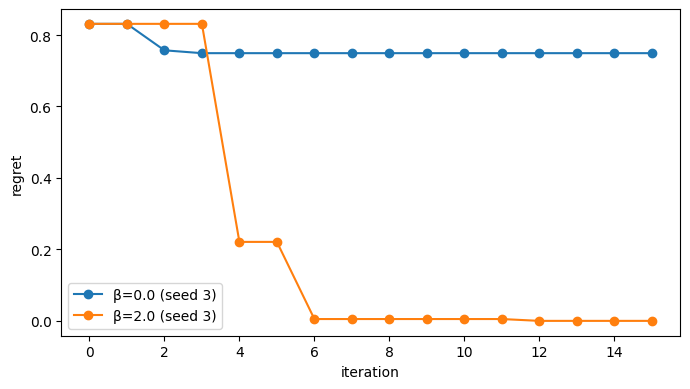

In [19]:
def f(x):
    return jnp.sin(3 * jnp.pi * x[:, 0]) + 0.5 * jnp.sin(7 * jnp.pi * x[:, 0])

def k_SE(x1, x2, params):
    l, sigma_f = params
    diff = x1[:, None, :] - x2[None, :, :]
    return (sigma_f ** 2) * jnp.exp(-jnp.sum(diff ** 2, axis=-1) / (2 * l ** 2))

def ucb(mu, sigma, beta):
    return mu + beta * sigma

def gp_posterior(train_data, X_test, kernel, params, obs_noise=0.01):
    X_train, y_train = train_data
    n = len(X_train)
    K = kernel(X_train, X_train, params) + (obs_noise ** 2) * jnp.eye(n)
    K_s = kernel(X_train, X_test, params)
    K_ss = kernel(X_test, X_test, params)

    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y_train, lower=True), lower=False)

    mean = (K_s.T @ alpha).squeeze()
    v = solve_triangular(L, K_s, lower=True)
    cov = K_ss - v.T @ v
    return mean, cov

def run_bo(f, X_grid, n_init, n_iter, beta, params, key, obs_noise=0.01):
    key, subkey = jr.split(key)
    idx = jr.choice(subkey, X_grid.shape[0], (n_init,), replace=False)

    X, y = X_grid[idx], f(X_grid[idx])
    best_so_far = [float(jnp.max(y))]

    for _ in range(n_iter):
        mu, cov = gp_posterior((X, y), X_grid, k_SE, params, obs_noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))

        x_next = X_grid[jnp.argmax(ucb(mu, sigma, beta))][None, :]
        y_next = f(x_next)

        X = jnp.concatenate([X, x_next])
        y = jnp.concatenate([y, y_next])
        best_so_far.append(float(jnp.max(y)))

    return X, y, jnp.array(best_so_far)

X_grid = jnp.linspace(0, 1, 200)[:, None]
f_max = float(jnp.max(f(X_grid)))
params = (jnp.array([0.15]), jnp.array([1.0]))

plt.figure(figsize=(7, 4))

for beta in [0.0, 2.0]:
    for seed in [1, 2, 3]:
        Xb, yb, best = run_bo(f, X_grid, n_init=3, n_iter=15, beta=beta,
                              params=params, key=jr.PRNGKey(seed))
        print(f'β={beta}, seed={seed}: final regret = {f_max - float(best[-1]):.3f}')
        print('   picks:', [round(float(v), 2) for v in Xb[3:, 0].tolist()])

    plt.plot(f_max - best, 'o-', label=f'β={beta} (seed 3)')

plt.xlabel('iteration')
plt.ylabel('regret')
plt.legend()
plt.tight_layout()
plt.show()


### 3b. Fitting the GP hyperparameters with the marginal likelihood

In [18]:
def f(x):
    return jnp.sin(3 * jnp.pi * x[:, 0]) + 0.5 * jnp.sin(7 * jnp.pi * x[:, 0])

def k_SE(x1, x2, params):
    l, sf = params
    return (sf ** 2) * jnp.exp(-jnp.sum((x1[:, None, :] - x2[None, :, :]) ** 2, axis=-1) / (2 * l ** 2))

def gp_posterior(data, X_test, kernel, params, noise=0.01):
    X, y = data
    K = kernel(X, X, params) + (noise ** 2) * jnp.eye(len(X))
    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)
    K_s = kernel(X, X_test, params)
    return (K_s.T @ alpha).squeeze(), kernel(X_test, X_test, params) - solve_triangular(L, K_s, lower=True).T @ solve_triangular(L, K_s, lower=True)

def ucb(mu, sigma, beta):
    return mu + beta * sigma

def run_bo(f, X_grid, n_init, n_iter, beta, params, key, noise=0.01):
    key, subkey = jr.split(key)
    idx = jr.choice(subkey, X_grid.shape[0], (n_init,), replace=False)
    X, y = X_grid[idx], f(X_grid[idx])
    best = [float(jnp.max(y))]

    for _ in range(n_iter):
        mu, cov = gp_posterior((X, y), X_grid, k_SE, params, noise)
        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov), 0.0))
        x_next = X_grid[jnp.argmax(ucb(mu, sigma, beta))][None, :]
        X, y = jnp.concatenate([X, x_next]), jnp.concatenate([y, f(x_next)])
        best.append(float(jnp.max(y)))

    return X, y, jnp.array(best)

In [17]:
ELL_GRID = jnp.logspace(-2, 0, 40)
SF_GRID = jnp.logspace(-1, 1, 30)

def nlml(ell, sf, X, y, noise=0.01):
    K = k_SE(X, X, (ell, sf)) + (noise**2 + 1e-6) * jnp.eye(len(X))
    L = jnp.linalg.cholesky(K)
    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)
    return 0.5 * (y @ alpha) + jnp.sum(jnp.log(jnp.diag(L))) + 0.5 * len(X) * jnp.log(2 * jnp.pi)

def fit_hyperparams(X, y, noise=0.01):
    best_loss, best_params = jnp.inf, (1.0, 1.0)
    for ell in ELL_GRID:
        for sf in SF_GRID:
            loss = nlml(ell, sf, X, y, noise)
            if jnp.isfinite(loss) and loss < best_loss:
                best_loss, best_params = loss, (ell, sf)
    return jnp.array([best_params[0]]), jnp.array([best_params[1]])


Fitting hyperparameters...
Optimal lengthscale: 0.094 | signal std: 0.672
Running vmap for NLML curve...


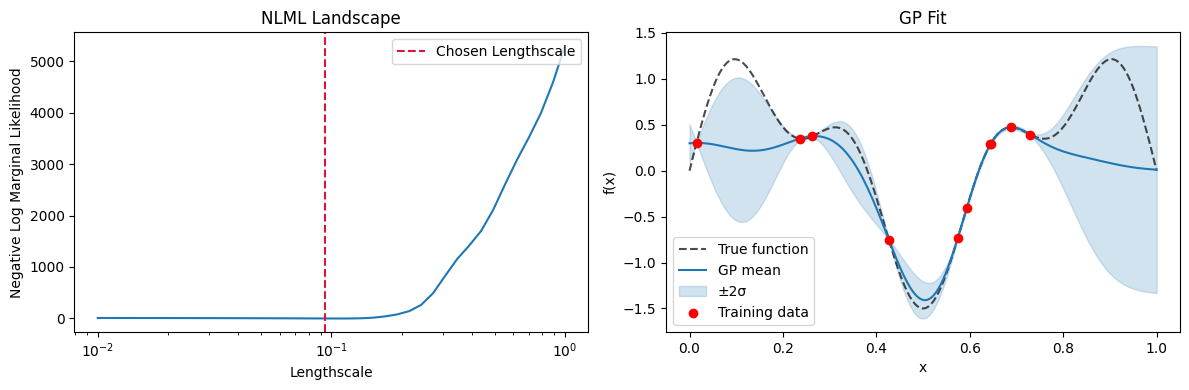

In [16]:
key = jr.PRNGKey(42)
X10 = jr.uniform(key, (10, 1))
y10 = f(X10)

print("Fitting hyperparameters...")
best_ell, best_sf = fit_hyperparams(X10, y10)
print(f"Optimal lengthscale: {float(best_ell[0]):.3f} | signal std: {float(best_sf[0]):.3f}")

print("Running vmap for NLML curve...")
nlml_curve = jax.vmap(lambda e: nlml(e, 1.0, X10, y10))(ELL_GRID)

mu, cov_matrix = gp_posterior((X10, y10), X_test, k_SE, (best_ell, best_sf))
std_dev = jnp.sqrt(jnp.clip(jnp.diag(cov_matrix), min=0.0))

fig, (ax_nlml, ax_gp) = plt.subplots(1, 2, figsize=(12, 4))

ax_nlml.semilogx(ELL_GRID, nlml_curve, color='tab:blue')
ax_nlml.axvline(float(best_ell[0]), color='crimson', linestyle='--', label='Chosen Lengthscale')
ax_nlml.set_xlabel('Lengthscale')
ax_nlml.set_ylabel('Negative Log Marginal Likelihood')
ax_nlml.legend(loc='upper right')
ax_nlml.set_title("NLML Landscape")

ax_gp.plot(X_test[:, 0], f(X_test), 'k--', label='True function', alpha=0.7)
ax_gp.plot(X_test[:, 0], mu, color='tab:blue', label='GP mean')

upper_bound = mu + 2 * std_dev
lower_bound = mu - 2 * std_dev
ax_gp.fill_between(X_test[:, 0], lower_bound, upper_bound, color='tab:blue', alpha=0.2, label='±2σ')
ax_gp.scatter(X10[:, 0], y10, color='red', zorder=5, label='Training data')
ax_gp.set_xlabel('x')
ax_gp.set_ylabel('f(x)')
ax_gp.legend(loc='lower left')
ax_gp.set_title("GP Fit")

plt.tight_layout()
plt.show()

### 4. Comparing acquisition functions: greedy, UCB and Thompson sampling

Strategy: greedy --> final mean regret: 0.6060 (1/5 converged)
Strategy: ucb --> final mean regret: 0.0000 (5/5 converged)
Strategy: thompson --> final mean regret: 0.0000 (5/5 converged)


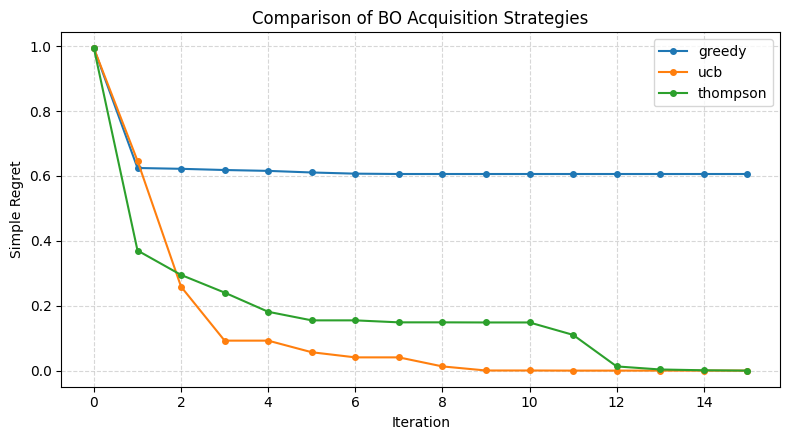

In [23]:
def run_bo_method(objective_fn, X_pool, strategy, n_init, steps, rng_key, beta_val=2.0, noise=0.01):

    rng_key, subkey = jr.split(rng_key)
    init_idx = jr.choice(subkey, len(X_pool), (n_init,), replace=False)

    X_train = X_pool[init_idx]
    y_train = objective_fn(X_train)


    best_history = [float(jnp.max(y_train))]

    for step in range(steps):

        gp_params = fit_hyperparams(X_train, y_train, noise)
        mu, cov_mat = gp_posterior((X_train, y_train), X_pool, k_SE, gp_params, noise)


        std_dev = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

        rng_key, subkey = jr.split(rng_key)


        if strategy == "greedy":
            acquisition = mu
        elif strategy == "ucb":
            acquisition = mu + beta_val * std_dev
        else:
            acquisition = jr.multivariate_normal(
                subkey, mu, cov_mat + 1e-6 * jnp.eye(len(mu)), method="eigh"
            )

        # select next point to evaluate
        next_idx = jnp.argmax(acquisition)
        x_new = X_pool[next_idx][None, :]

        # update our training sets
        X_train = jnp.concatenate([X_train, x_new])
        y_train = jnp.concatenate([y_train, objective_fn(x_new)])

        best_history.append(float(jnp.max(y_train)))

    return jnp.array(best_history)


strategies = ["greedy", "ucb", "thompson"]
n_seeds = 5

plt.figure(figsize=(8, 4.5))

for strat in strategies:
    all_regrets = []

    for seed_val in range(n_seeds):
        best_vals = run_bo_method(
            f, X_grid, strat, n_init=3, steps=15, rng_key=jr.PRNGKey(seed_val)
        )
        all_regrets.append(f_max - best_vals)

    all_regrets = jnp.stack(all_regrets)
    mean_regret = all_regrets.mean(axis=0)


    successes = int((all_regrets[:, -1] < 0.01).sum())
    print(f"Strategy: {strat} --> final mean regret: {float(mean_regret[-1]):.4f} ({successes}/{n_seeds} converged)")

    plt.plot(mean_regret, marker='o', markersize=4, label=strat)

plt.title("Comparison of BO Acquisition Strategies")
plt.xlabel("Iteration")
plt.ylabel("Simple Regret")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 5. Effect of β: from exploitation to exploration

beta: -1.0 -> final regret: 0.366
beta: 0.0 -> final regret: 0.303
beta: 0.5 -> final regret: 0.074
beta: 2.0 -> final regret: 0.000
beta: 5.0 -> final regret: 0.000
beta: 10.0 -> final regret: 0.000


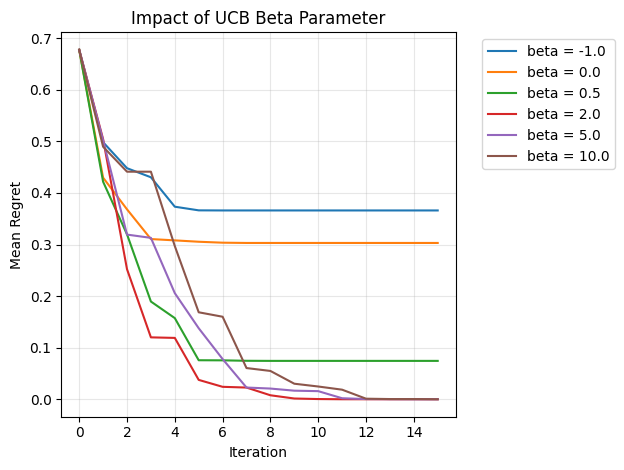

In [24]:
# let's see how changing beta affects UCB (negative beta = crazy, high beta = super exploratory)
for beta in [-1.0, 0.0, 0.5, 2.0, 5.0, 10.0]:
    regrets = []

    for seed in range(10):
        best_values = run_bo_method(
            f, X_grid, "ucb", 3, 15, jr.PRNGKey(seed), beta_val=beta
        )
        regrets.append(f_max - best_values)

    regrets = jnp.stack(regrets)
    mean_regret = regrets.mean(axis=0)

    print(f"beta: {beta} -> final regret: {float(mean_regret[-1]):.3f}")

    plt.plot(mean_regret, label=f"beta = {beta}")

plt.title("Impact of UCB Beta Parameter")
plt.xlabel("Iteration")
plt.ylabel("Mean Regret")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### 6. Bayesian optimization on the Ackley function (2D)

In [25]:
def run_bo_method(f, X_grid, method, n_init, n_iter, key, beta=2.0, obs_noise=0.01, norm=False):

    key, subkey = jr.split(key)
    init_idx = jr.choice(subkey, len(X_grid), (n_init,), replace=False)

    X = X_grid[init_idx]
    y = f(X)


    best_vals = [float(jnp.max(y))]

    for i in range(n_iter):

        if norm:
            yn = (y - y.mean()) / (y.std() + 1e-8)
        else:
            yn = y

        gp_params = fit_hyperparams(X, yn, obs_noise)
        mu, cov_mat = gp_posterior((X, yn), X_grid, k_SE, gp_params, obs_noise)

        sigma = jnp.sqrt(jnp.clip(jnp.diag(cov_mat), 0.0))

        key, subkey = jr.split(key)

        # acquisition function choice
        if method == "greedy":
            acq = mu
        elif method == "ucb":
            acq = mu + beta * sigma
        else:
            jitter = 1e-6 * jnp.eye(len(mu))
            acq = jr.multivariate_normal(
                subkey, mu, cov_mat + jitter, method="eigh"
            )


        next_idx = jnp.argmax(acq)
        x_new = X_grid[next_idx][None, :]

        X = jnp.concatenate([X, x_new])
        y = jnp.concatenate([y, f(x_new)])

        current_best = float(jnp.max(y))
        best_vals.append(current_best)

    return jnp.array(best_vals)

Max value found on grid: -0.0000


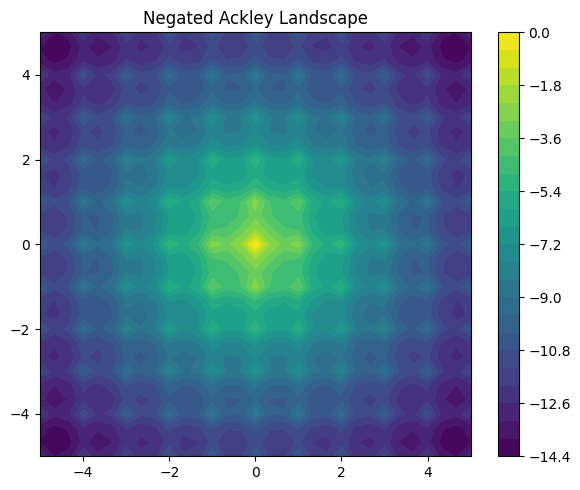

[GREEDY] Final Regret: 5.522 | Converged: 1/5
[UCB] Final Regret: 0.471 | Converged: 4/5
[THOMPSON] Final Regret: 2.083 | Converged: 2/5


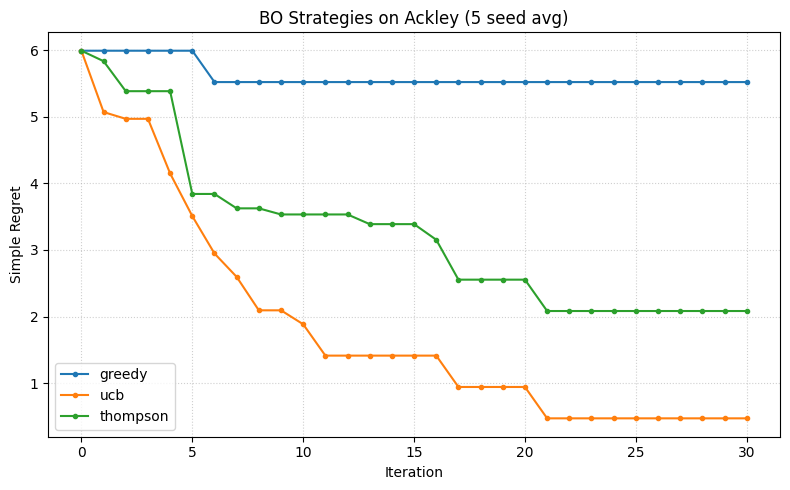

In [26]:
# define 2D ackley
def ackley(X):
    x1, x2 = X[:, 0], X[:, 1]
    term1 = -20 * jnp.exp(-0.2 * jnp.sqrt((x1**2 + x2**2) / 2))
    term2 = -jnp.exp((jnp.cos(2*jnp.pi*x1) + jnp.cos(2*jnp.pi*x2)) / 2)
    return -(term1 + term2 + 20 + jnp.e)


g = jnp.linspace(-5, 5, 31)
G1, G2 = jnp.meshgrid(g, g)
X2 = jnp.stack([G1.ravel(), G2.ravel()], axis=1)


grid_vals = ackley(X2)
a_max = jnp.max(grid_vals)
print(f"Max value found on grid: {a_max:.4f}")


plt.figure(figsize=(6, 5))
plt.contourf(G1, G2, grid_vals.reshape(31, 31), levels=25, cmap="viridis")
plt.colorbar()
plt.title("Negated Ackley Landscape")
plt.tight_layout()
plt.show()

methods = ["greedy", "ucb", "thompson"]
n_runs = 5

plt.figure(figsize=(8, 5))

for m in methods:
    all_regrets = []

    for s in range(n_runs):
        best_vals = run_bo_method(
            ackley, X2, m, n_init=5, n_iter=30, key=jr.PRNGKey(s), norm=True
        )
        all_regrets.append(a_max - best_vals)

    all_regrets = jnp.stack(all_regrets)
    mean_regret = all_regrets.mean(axis=0)


    converged = int((all_regrets[:, -1] < 0.01).sum())
    print(f"[{m.upper()}] Final Regret: {float(mean_regret[-1]):.3f} | Converged: {converged}/{n_runs}")

    plt.plot(mean_regret, marker='o', markersize=3, label=m)

plt.title("BO Strategies on Ackley (5 seed avg)")
plt.xlabel("Iteration")
plt.ylabel("Simple Regret")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

### 7. Kernel choice and fully Bayesian hyperparameters

In [29]:
def k_matern52(x1, x2, params):
    ell, sf = params

    diff = x1[:, None, :] - x2[None, :, :]
    dist = jnp.sqrt(jnp.sum(diff**2, axis=-1) + 1e-12) / ell

    factor = 1.0 + jnp.sqrt(5.0) * dist + (5.0 / 3.0) * (dist**2)
    return (sf**2) * factor * jnp.exp(-jnp.sqrt(5.0) * dist)


def nlml(ell, sf, X, y, kernel, obs_noise=0.01):
    K = kernel(X, X, (ell, sf))
    K += (obs_noise**2 + 1e-6) * jnp.eye(len(X))

    L = jnp.linalg.cholesky(K)

    alpha = solve_triangular(L.T, solve_triangular(L, y, lower=True), lower=False)


    data_fit = 0.5 * y @ alpha
    complexity = jnp.sum(jnp.log(jnp.diag(L)))
    constant = 0.5 * len(X) * jnp.log(2 * jnp.pi)

    return data_fit + complexity + constant

kernels_to_test = [("SE", k_SE), ("Matérn 5/2", k_matern52)]

print("Starting hyperparameter tuning grid search...")
for name, kernel in kernels_to_test:
    scores = []
    for ell in ELL_GRID:
        row = [nlml(ell, sf, X10, y10, kernel) for sf in SF_GRID]
        scores.append(row)

    scores = jnp.array(scores)


    best_flat_idx = jnp.argmin(scores)
    best_i, best_j = jnp.unravel_index(best_flat_idx, scores.shape)

    best_ell = ELL_GRID[best_i]
    best_sf = SF_GRID[best_j]
    min_loss = scores[best_i, best_j]

    print(f"--> {name} Optimal -> lengthscale: {float(best_ell):.3f}, signal_std: {float(best_sf):.3f}, NLML: {float(min_loss):.2f}")

Starting hyperparameter tuning grid search...
--> SE Optimal -> lengthscale: 0.094, signal_std: 0.672, NLML: -3.18
--> Matérn 5/2 Optimal -> lengthscale: 0.119, signal_std: 0.574, NLML: -1.66


Running MCMC chain...
Done! Acceptance rate: 0.40
90% credible interval for lengthscale: [0.038, 0.124]


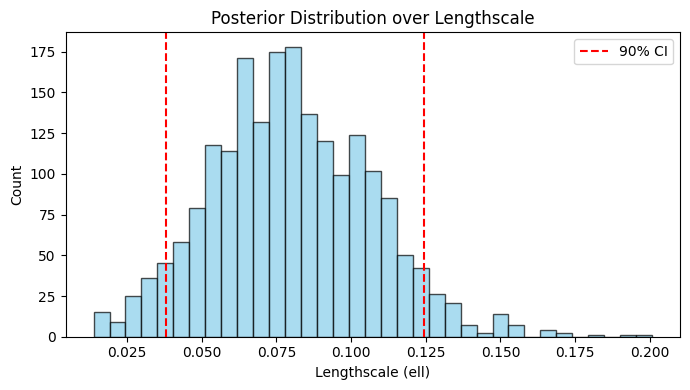

In [30]:
X5 = jr.uniform(jr.PRNGKey(3), (5, 1))
y5 = f(X5)

def log_posterior(theta):
    ell, sf = jnp.exp(theta)
    prior = -0.5 * jnp.sum((theta - jnp.log(jnp.array([0.2, 1.0])))**2)


    return -nlml(ell, sf, X5, y5, k_SE) + prior


key = jr.PRNGKey(0)
current_theta = jnp.log(jnp.array([0.2, 1.0]))
chain_samples = []

print("Running MCMC chain...")
n_steps = 3000
accepted_count = 0

for step in range(n_steps):
    key, k_sub1, k_sub2 = jr.split(key, 3)


    proposal = current_theta + 0.5 * jr.normal(k_sub1, (2,))


    log_accept_ratio = log_posterior(proposal) - log_posterior(current_theta)

    if jnp.log(jr.uniform(k_sub2)) < log_accept_ratio:
        current_theta = proposal
        accepted_count += 1

    chain_samples.append(jnp.exp(current_theta))

print(f"Done! Acceptance rate: {accepted_count / n_steps:.2f}")

burn_in = 1000
ells = jnp.stack(chain_samples[burn_in:])[:, 0]

ci_90 = jnp.percentile(ells, jnp.array([5, 95]))
print(f"90% credible interval for lengthscale: [{ci_90[0]:.3f}, {ci_90[1]:.3f}]")


plt.figure(figsize=(7, 4))
plt.hist(ells, bins=35, color='skyblue', edgecolor='black', alpha=0.7)
plt.axvline(float(ci_90[0]), color='red', linestyle='--', label='90% CI')
plt.axvline(float(ci_90[1]), color='red', linestyle='--')
plt.xlabel("Lengthscale (ell)")
plt.ylabel("Count")
plt.title("Posterior Distribution over Lengthscale")
plt.legend()
plt.tight_layout()
plt.show()